In [1]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

In [2]:
# ==============================================================================
# 1. LOAD DATA (ECONOPHYSICS FEATURES ONLY)
# ==============================================================================
print("Loading Econophysics Features...")
# Load the dataset generated in Notebook 06a
X_phys = pd.read_parquet('../data/processed/features_econophysics.parquet')
y_train = pd.read_parquet('../data/raw/y_train.parquet')

# Ensure perfect alignment between features and target using the index ('id')
y = y_train.loc[X_phys.index]['structural_breakpoint']

print(f"Features shape: {X_phys.shape}")
print(f"Target shape: {y.shape}")

# Calculate the exact class imbalance ratio for the XGBoost scale_pos_weight
imbalance_ratio = (y == 0).sum() / (y == 1).sum()
print(f"Class imbalance ratio (False/True): {imbalance_ratio:.4f}")

Loading Econophysics Features...
Features shape: (10001, 6)
Target shape: (10001,)
Class imbalance ratio (False/True): 2.4380


In [3]:
# ==============================================================================
# 2. MODEL EVALUATION (5-FOLD CROSS VALIDATION)
# ==============================================================================
# Base parameters adjusted for a very small feature space (6 variables)
base_params = {
    'n_estimators': 300, 
    'learning_rate': 0.05, 
    'max_depth': 4, # Shallower trees to prevent overfitting on few features
    'subsample': 0.8, 
    'colsample_bytree': 0.9, 
    'scale_pos_weight': imbalance_ratio, 
    'eval_metric': 'auc', 
    'random_state': 42, 
    'n_jobs': -1,
    'enable_categorical': True
}

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
xgb_model = xgb.XGBClassifier(**base_params)

print("\n" + "="*50)
print("EVALUATING MODEL: ECONOPHYSICS FEATURES ONLY (6 Features)")
print("="*50)

# Calculate ROC AUC
scores_auc = cross_val_score(xgb_model, X_phys, y, cv=cv_strategy, scoring='roc_auc', n_jobs=-1)
mean_auc = np.mean(scores_auc)
std_auc = np.std(scores_auc)

print(f"Mean ROC AUC: {mean_auc:.4f} (+/- {std_auc:.4f})")

# Generate cross-validated predictions for the detailed report
y_pred_cv = cross_val_predict(xgb_model, X_phys, y, cv=cv_strategy, n_jobs=-1)

print("\nCLASSIFICATION REPORT:")
print(classification_report(y, y_pred_cv, digits=4))


EVALUATING MODEL: ECONOPHYSICS FEATURES ONLY (6 Features)
Mean ROC AUC: 0.5222 (+/- 0.0101)

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

       False     0.7198    0.6488    0.6824      7092
        True     0.3098    0.3843    0.3431      2909

    accuracy                         0.5718     10001
   macro avg     0.5148    0.5165    0.5127     10001
weighted avg     0.6005    0.5718    0.5837     10001



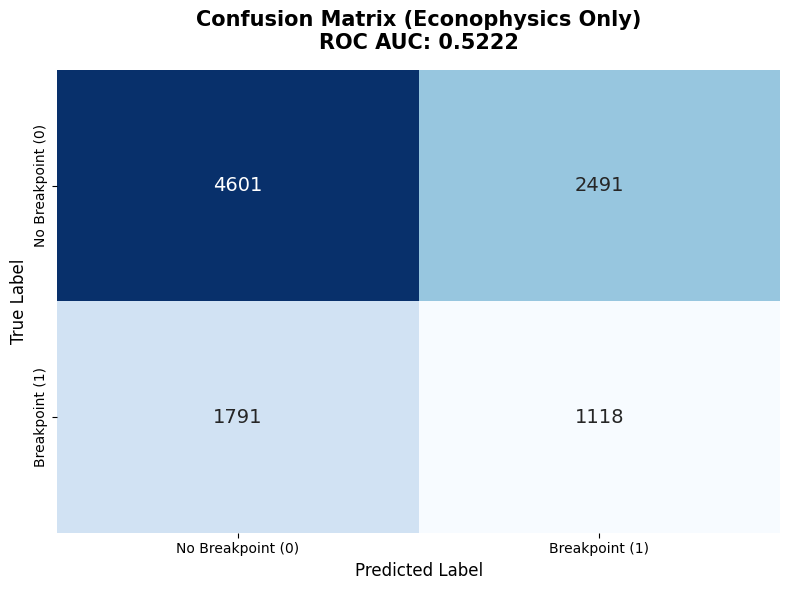

In [4]:
# ==============================================================================
# 3. CONFUSION MATRIX VISUALIZATION
# ==============================================================================
cm = confusion_matrix(y, y_pred_cv)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['No Breakpoint (0)', 'Breakpoint (1)'],
            yticklabels=['No Breakpoint (0)', 'Breakpoint (1)'],
            annot_kws={"size": 14})

plt.title(f'Confusion Matrix (Econophysics Only)\nROC AUC: {mean_auc:.4f}', 
          fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()


Extracting Econophysics Feature Importances...


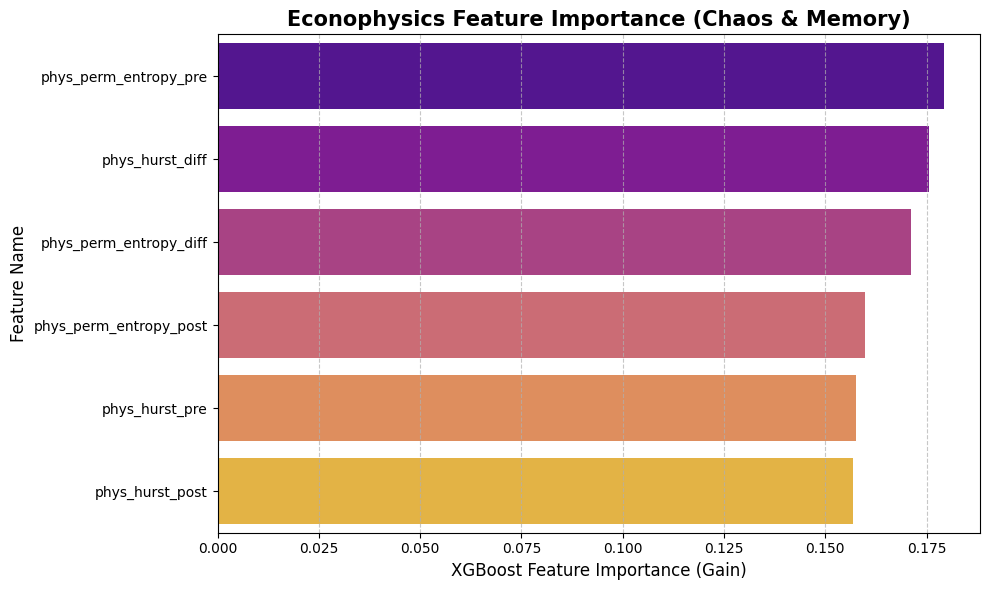


Exact Feature Importance Weights:


,Feature,Importance
0,phys_perm_entropy_pre,0.179208
1,phys_hurst_diff,0.175597
2,phys_perm_entropy_diff,0.171085
3,phys_perm_entropy_post,0.159723
4,phys_hurst_pre,0.157556
5,phys_hurst_post,0.156830


In [5]:
# ==============================================================================
# 4. FEATURE IMPORTANCE ANALYSIS
# ==============================================================================
print("\nExtracting Econophysics Feature Importances...")

# Fit the model on the entire dataset to extract the global importance
xgb_model.fit(X_phys, y)

importances = xgb_model.feature_importances_
df_importances = pd.DataFrame({
    'Feature': X_phys.columns, 
    'Importance': importances
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

# Visualize the importances
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=df_importances, palette='plasma')

plt.title('Econophysics Feature Importance (Chaos & Memory)', fontsize=15, fontweight='bold')
plt.xlabel('XGBoost Feature Importance (Gain)', fontsize=12)
plt.ylabel('Feature Name', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

print("\nExact Feature Importance Weights:")
display(df_importances)